<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [National Weather Service](https://github.com/Query-farm/vgi-nws)

Explore US weather alerts, observations, forecast grids, bulletins, and river conditions.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-nws/blob/main/notebooks/05_a_short_rating_is_not_a_complete_curve.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-nws/blob/main/notebooks/README.md)


## 05 · A short rating is not a complete curve

A row limit changes which rating points you receive; it does not change a river's
stage-to-flow relationship. Separately, a model reach can return members and a mean,
which must not be summed as independent flows. We inspect these two boundaries before
reading a river summary. All numbers are synthetic and unsuitable for operational use.

### Set a bounded rating request

Use **RATING_LIMIT = 2**, then try **8**. The synthetic source contains five rating
points. A second fixed request with limit eight supplies a complete reference for this
fixture; that is not a general guarantee that eight rows exhaust a real rating curve.
`possibly_truncated` is a conservative limit flag, not an exact count of missing rows.

In [1]:
RATING_LIMIT = 2  # Experiment: 8; integer range 1–8

### Run independently

Read the saved results on GitHub or choose **Open in Colab** and Run All. The brief
base install preserves compatible preloaded plotting and kernel libraries. Local
publication uses the optional `[runner]` extra. Initial packages, verified companions,
VGI and native worker download need internet. No worker checkout, Bun or source build
is required. Hosted Colab is not tested; a fresh preloaded Python 3.12 notebook-only
execution checks the common setup path. [Detailed setup and provenance](README.md).

In [2]:
import importlib.metadata as packages

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.40":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.40"
from vgi_notebooks import check_runtime

check_runtime()
if packages.version("vgi-example-notebooks") != "0.3.40":
    raise RuntimeError("Install shared tools 0.3.40, restart, and Run All.")

In [3]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from vgi_notebooks import prepare
from vgi_notebooks.presentation import finish, prose, theme
from vgi_notebooks.session import connect

prepare("nws")
from scenario_source import ScenarioSource

%matplotlib inline
theme()
session = connect(globals())
con = session.connection
assert con.execute("SELECT name FROM duckdb_secrets()").fetchall() == []
assert con.execute("SELECT current_setting('TimeZone')").fetchone()[0] == "UTC"
source = ScenarioSource()
Path("artifacts").mkdir(exist_ok=True)
PROVENANCE = "Source: synthetic NOAA-shaped teaching inputs · 2 January 2026 UTC · not live conditions"

if type(RATING_LIMIT) is not int or not 1 <= RATING_LIMIT <= 8:
    raise ValueError("RATING_LIMIT must be an integer from 1 through 8")

### Source boundary

Every value in this story is **synthetic**. The real released NWS worker parses
NOAA-shaped documents served only on loopback; all ten upstream roots are scoped to
that local service and unknown requests fail. No real alert, gauge condition or forecast
is represented. Canonical `source_url` values are emitted by the worker even in this
mode: they describe product routes, not proof of a live request. `fetched_at` is the
local read time. The fixture's fixed scenario time is **2026-01-02 12:00 UTC**.

Shared setup uses an empty temporary SQL-secret directory, disables persistence and
JupySQL default connection autoload, and fixes the connection timezone to UTC. No key,
saved secret or account write is involved. Cleanup closes the connection/service and
restores the temporary process environment.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'nws' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-nws@v0.4.0');

,Success


### Check the requested extent before using the points

Request the limited rating with named options and positional JSON. The `compat`
interface is useful for clients that need JSON options on correlated calls; the two
interfaces must return the same business values for the same request. A fixed reference
shows what this teaching source withheld under the smaller limit. The figure displays
returned points only, without fitting, interpolating or extrapolating a discharge curve.

In [5]:
%%sql
CREATE TABLE rating_selected AS SELECT * FROM nws.main.rating_curve('RMDV2',row_limit:={{RATING_LIMIT}});
CREATE TABLE rating_compat AS SELECT * FROM nws.compat.rating_curve('RMDV2',json_object('row_limit',{{RATING_LIMIT}}));
CREATE TABLE rating_reference AS SELECT * FROM nws.main.rating_curve('RMDV2',row_limit:=8);
SELECT 'requested' AS request,count(*) AS returned_points,min(stage) AS min_stage_ft,max(stage) AS max_stage_ft,
 bool_or(possibly_truncated) AS possibly_truncated FROM rating_selected
UNION ALL SELECT 'fixed reference',count(*),min(stage),max(stage),bool_or(possibly_truncated) FROM rating_reference;
SELECT stage,stage_unit,flow,flow_unit,possibly_truncated FROM rating_selected ORDER BY stage;

,stage,stage_unit,flow,flow_unit,possibly_truncated
0,8.0,ft,16000.0,cfs,True
1,9.0,ft,18000.0,cfs,True


In [6]:
%%sql rating <<
SELECT r.stage,r.flow,EXISTS(SELECT 1 FROM rating_selected s WHERE s.stage=r.stage AND s.flow=r.flow) AS selected FROM rating_reference r ORDER BY stage;

In [7]:
n_selected = int(rating.selected.sum())
truncated = bool(con.execute("SELECT bool_or(possibly_truncated) FROM rating_selected").fetchone()[0])
prose(
    f"The limit of **{RATING_LIMIT}** returns **{n_selected} of {len(rating)} fixture points**, with `possibly_truncated = {str(truncated).lower()}`. The reference spans **{rating.stage.min():g}–{rating.stage.max():g} ft**; the selected extent is shown above. The flag describes this request, not a verified hydrologic domain."
)

The limit of **2** returns **2 of 5 fixture points**, with `possibly_truncated = true`. The reference spans **8–15 ft**; the selected extent is shown above. The flag describes this request, not a verified hydrologic domain.

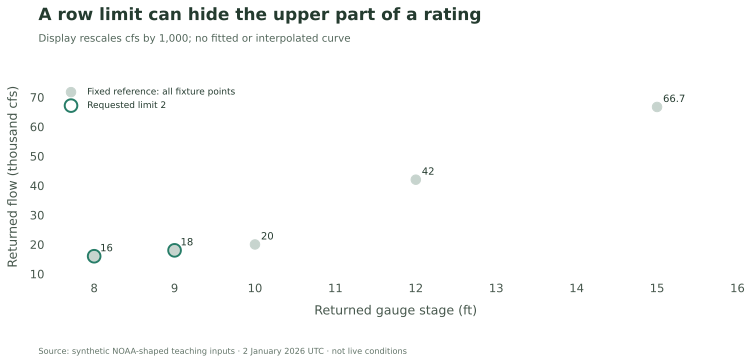

In [8]:
fig, ax = plt.subplots(figsize=(10.8, 5.3))
ax.scatter(
    rating.stage, rating.flow / 1000, s=90, color="#C7D4CE", label="Fixed reference: all fixture points"
)
r = rating[rating.selected]
ax.scatter(
    r.stage,
    r.flow / 1000,
    s=160,
    facecolors="none",
    edgecolors="#287D68",
    linewidths=2,
    label=f"Requested limit {RATING_LIMIT}",
)
for row in rating.itertuples():
    ax.annotate(
        f"{row.flow / 1000:g}",
        (row.stage, row.flow / 1000),
        xytext=(6, 5),
        textcoords="offset points",
        fontsize=10,
    )
ax.set(
    xlabel="Returned gauge stage (ft)", ylabel="Returned flow (thousand cfs)", xlim=(7.5, 16), ylim=(10, 76)
)
ax.legend(loc="upper left", fontsize=9)
finish(
    fig,
    "A row limit can hide the upper part of a rating",
    "Display rescales cfs by 1,000; no fitted or interpolated curve",
    PROVENANCE,
    name=f"rating-limit-{RATING_LIMIT}",
)

### Keep reach members separate from the reported mean

A model reach is a different identifier and product from the gauge rating. Its metadata
lists available series and adjacent model reaches; it does not guarantee values at every
forecast time. The long-range product retains `member`, reference time and valid time.
The same six rows arrive through named and positional options.

In this constructed example the first mean equals the average of the two members.
That arithmetic is a fixture check, not an assumption about how every production mean
is generated. The mean is a summary alongside members, so adding all three double-counts
information. All values at the next valid time are NULL, which means missing, not zero.

In [9]:
%%sql
CREATE TABLE reach_detail AS SELECT * FROM nws.main.reach('8574021');
CREATE TABLE modeled AS SELECT * FROM nws.main.reach_streamflow('8574021',series:='long_range');
CREATE TABLE modeled_compat AS SELECT * FROM nws.compat.reach_streamflow('8574021','{"series":"long_range"}');
SELECT reach_id,name,available_series_json,upstream_json,downstream_json FROM reach_detail;
SELECT valid_at,count(*) AS member_and_mean_rows,count(flow) AS available_values,
 max(flow) FILTER(WHERE member='mean') AS reported_mean,
 avg(flow) FILTER(WHERE member<>'mean') AS available_member_average,any_value(flow_unit) AS native_unit
FROM modeled GROUP BY valid_at ORDER BY valid_at;
SELECT member,reference_at,valid_at,flow,flow_unit FROM modeled ORDER BY valid_at,member;

,member,reference_at,valid_at,flow,flow_unit
0,mean,2026-01-02 12:00:00+00:00,2026-01-02 13:00:00+00:00,100.0,ft³/s
1,member1,2026-01-02 12:00:00+00:00,2026-01-02 13:00:00+00:00,80.0,ft³/s
2,member2,2026-01-02 12:00:00+00:00,2026-01-02 13:00:00+00:00,120.0,ft³/s
3,mean,2026-01-02 12:00:00+00:00,2026-01-02 14:00:00+00:00,NaN,ft³/s
4,member1,2026-01-02 12:00:00+00:00,2026-01-02 14:00:00+00:00,NaN,ft³/s
5,member2,2026-01-02 12:00:00+00:00,2026-01-02 14:00:00+00:00,NaN,ft³/s


In [10]:
%%sql modeled <<
SELECT * EXCLUDE(source_url,fetched_at) FROM modeled ORDER BY valid_at,member;

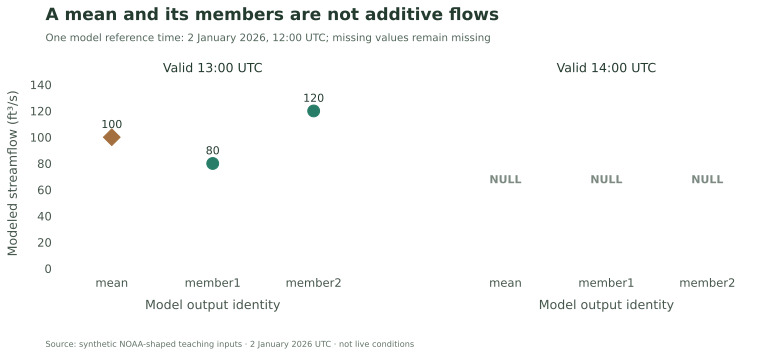

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2), sharey=True)
for ax, (time, rows) in zip(axes, modeled.groupby("valid_at", sort=True), strict=True):
    rows = rows.sort_values("member")
    for i, r in enumerate(rows.itertuples()):
        if pd.isna(r.flow):
            ax.text(i, 65, "NULL", ha="center", color="#7C8A82", weight="bold")
        else:
            ax.scatter(
                i,
                r.flow,
                s=140,
                marker="D" if r.member == "mean" else "o",
                color="#A46F3E" if r.member == "mean" else "#287D68",
            )
            ax.text(i, r.flow + 7, f"{r.flow:g}", ha="center")
    ax.set(
        xticks=range(len(rows)),
        xticklabels=rows.member,
        xlim=(-0.5, 2.5),
        ylim=(0, 145),
        title=time.strftime("Valid %H:%M UTC"),
        xlabel="Model output identity",
    )
axes[0].set_ylabel("Modeled streamflow (ft³/s)")
finish(
    fig,
    "A mean and its members are not additive flows",
    "One model reference time: 2 January 2026, 12:00 UTC; missing values remain missing",
    PROVENANCE,
    name="reach-members",
)

### Read the summary as a statement, not another time series

`river_at_a_glance` uses a read-only API POST for a requested gauge list. Here that POST
is confined to the loopback fixture and accepts only RMDV2. Its positional counterpart
returns the same summary. The retained statement says 14 ft at 14:00, but is not a model
reach member or a reconstructed rating point. We display its original text and units
instead of mixing it into the streamflow chart.

In [12]:
%%sql
CREATE TABLE summary AS SELECT * FROM nws.main.river_at_a_glance('RMDV2');
CREATE TABLE summary_compat AS SELECT * FROM nws.compat.river_at_a_glance('RMDV2','{}');
SELECT gauge_id,name,office_id,rfc_id,
 json_extract_string(flood_statements_json,'$[0].text') AS statement,
 json_extract(flood_statements_json,'$[0].stage') AS statement_stage,
 json_extract_string(flood_statements_json,'$[0].units') AS statement_unit,
 json_extract_string(flood_statements_json,'$[0].validTime') AS statement_time FROM summary;

,gauge_id,name,office_id,rfc_id,statement,statement_stage,statement_unit,statement_time
0,RMDV2,Synthetic river summary,AKQ,MARFC,Synthetic summary only,14,ft,2026-01-02T14:00:00Z


In [13]:
%%sql checks <<
SELECT 'rating interface equivalence' AS check_name,NOT EXISTS((SELECT * EXCLUDE(source_url,fetched_at) FROM rating_selected EXCEPT SELECT * EXCLUDE(source_url,fetched_at) FROM rating_compat) UNION ALL (SELECT * EXCLUDE(source_url,fetched_at) FROM rating_compat EXCEPT SELECT * EXCLUDE(source_url,fetched_at) FROM rating_selected)) AS passed
UNION ALL SELECT 'requested population',count(*)=least({{RATING_LIMIT}},5) FROM rating_selected
UNION ALL SELECT 'reference population',count(*)=5 AND NOT bool_or(possibly_truncated) FROM rating_reference
UNION ALL SELECT 'conservative limit flag',bool_and(possibly_truncated=({{RATING_LIMIT}}<=5)) FROM rating_selected
UNION ALL SELECT 'native rating units',bool_and(stage_unit='ft' AND flow_unit='cfs') FROM rating_selected
UNION ALL SELECT 'selected points belong to reference',NOT EXISTS(SELECT stage,flow FROM rating_selected EXCEPT SELECT stage,flow FROM rating_reference)
UNION ALL SELECT 'reach identity and available series',count(*)=1 AND min(reach_id)='8574021' AND min(available_series_json)='["longRange"]' FROM reach_detail
UNION ALL SELECT 'model interface equivalence',NOT EXISTS((SELECT * EXCLUDE(source_url,fetched_at) FROM modeled EXCEPT SELECT * EXCLUDE(source_url,fetched_at) FROM modeled_compat) UNION ALL (SELECT * EXCLUDE(source_url,fetched_at) FROM modeled_compat EXCEPT SELECT * EXCLUDE(source_url,fetched_at) FROM modeled))
UNION ALL SELECT 'six distinct model identities',count(*)=6 AND count(DISTINCT(valid_at,member))=6 AND count(flow)=3 FROM modeled
UNION ALL SELECT 'fixture mean relationship',max(flow) FILTER(WHERE member='mean')=avg(flow) FILTER(WHERE member<>'mean') FROM modeled WHERE valid_at=TIMESTAMPTZ '2026-01-02 13:00:00+00'
UNION ALL SELECT 'missing next time retained',count(*)=3 AND count(flow)=0 FROM modeled WHERE valid_at=TIMESTAMPTZ '2026-01-02 14:00:00+00'
UNION ALL SELECT 'summary interface equivalence',NOT EXISTS((SELECT * EXCLUDE(source_url,fetched_at) FROM summary EXCEPT SELECT * EXCLUDE(source_url,fetched_at) FROM summary_compat) UNION ALL (SELECT * EXCLUDE(source_url,fetched_at) FROM summary_compat EXCEPT SELECT * EXCLUDE(source_url,fetched_at) FROM summary))
UNION ALL SELECT 'summary remains one gauge',count(*)=1 AND min(gauge_id)='RMDV2' FROM summary;

In [14]:
assert len(checks) == 13 and checks.passed.all()
requests = source.audit()
display(checks)
Path("artifacts/rating-audit.json").write_text(
    json.dumps(
        {
            "parameter": RATING_LIMIT,
            "rating": rating.to_dict("records"),
            "modeled": modeled.to_dict("records"),
            "checks": checks.to_dict("records"),
            "requests": requests,
        },
        indent=2,
        default=str,
    )
    + "\n"
)
prose(
    f"All **{len(checks)} SQL checks** pass across **{len(requests)} local requests**. No model value or river statement is used to fill missing observations or extend the rating."
)

,check_name,passed
0,rating interface equivalence,True
1,requested population,True
2,reference population,True
3,conservative limit flag,True
4,native rating units,True
5,selected points belong to reference,True
6,reach identity and available series,True
7,model interface equivalence,True
8,six distinct model identities,True
9,fixture mean relationship,True


All **13 SQL checks** pass across **5 local requests**. No model value or river statement is used to fill missing observations or extend the rating.

### Experiment: request enough rows for this fixture

Change **RATING_LIMIT from 2 to 8**. Returned rating points increase from two to five,
and the conservative truncation flag changes from true to false. The model population,
missing values and member figure remain identical. This establishes completeness for
the five-point teaching fixture only. Restore 2 afterward.

In [15]:
assert con.execute("SELECT name FROM duckdb_secrets()").fetchall() == []
session.close()
source.close()
plt.close("all")

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-nws](https://github.com/Query-farm/vgi-nws)